# Analisis Faktor yang Berhubungan dengan Math Score Siswa

**Pertanyaan:** Faktor apa yang berhubungan dengan math score siswa, dan seberapa baik math score bisa diprediksi dari data latar belakang dan test preparation course?

In [1]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Muat dan Periksa Data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats


df = pd.read_csv('StudentsPerformance.csv', skipinitialspace=True)   
# abaikan spasi setelah koma, sehingga tanda kutip dikenali
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
print(df.shape)





(1000, 8)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [5]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [6]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

## 2. Pembersihan Data

In [9]:
df.columns = df.columns.str.strip()                     # buang spasi di awal/akhir semua nama kolom

for col in df.select_dtypes(exclude='number').columns:  # isi sel kategori juga dirapikan
    df[col] = df[col].str.strip()

In [10]:
print(df['math score'].describe())

count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64


## 3. EDA

### 3a. Distribusi satu variabel

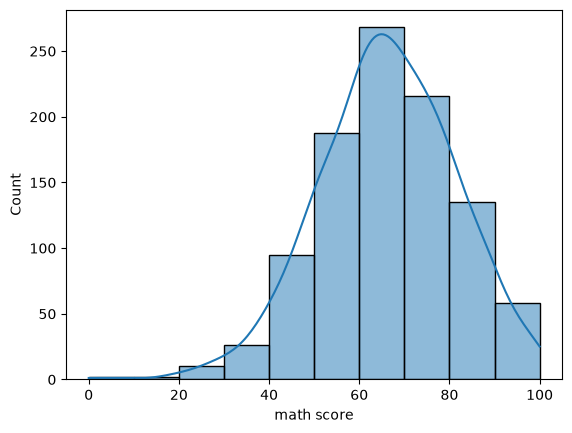

In [11]:
sns.histplot(x=df['math score'], bins=10, kde=True)

plt.show()

In [12]:
(df['math score'] < 30).sum()

np.int64(14)

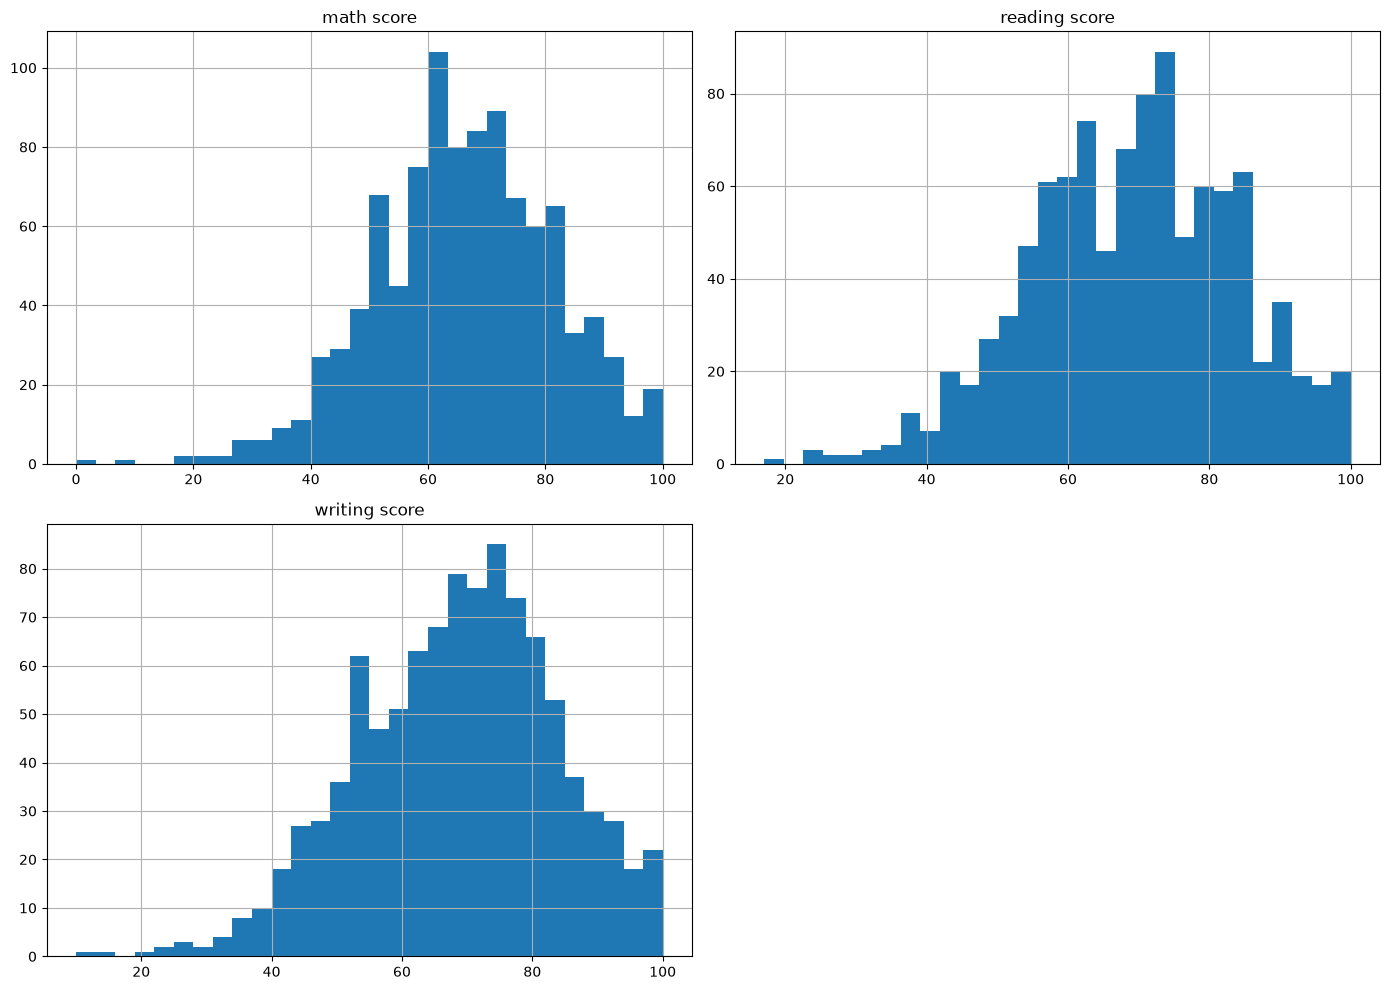

In [13]:
num_cols = df.select_dtypes('number').columns          # ambil nama semua kolom bertipe angka (int/float)
df[num_cols].hist(figsize=(14, 10), bins=30)           # buat satu histogram per kolom; ukuran kanvas 14x10; tiap histogram dibagi 30 batang
plt.tight_layout()                                     # rapikan jarak antar-grafik agar judul tidak bertabrakan
plt.show()                                             # tampilkan gambarnya

In [14]:
for col in df.select_dtypes(exclude='number').columns:         # untuk tiap kolom kategori
    print(df.groupby(col)['math score'].mean().sort_values())  # rata-rata target per kategori, urut dari terkecil




gender
female    63.633205
male      68.728216
Name: math score, dtype: float64
race/ethnicity
group A    61.629213
group B    63.452632
group C    64.463950
group D    67.362595
group E    73.821429
Name: math score, dtype: float64
parental level of education
high school           62.137755
some high school      63.497207
some college          67.128319
associate's degree    67.882883
bachelor's degree     69.389831
master's degree       69.745763
Name: math score, dtype: float64
lunch
free/reduced    58.921127
standard        70.034109
Name: math score, dtype: float64
test preparation course
none         64.077882
completed    69.695531
Name: math score, dtype: float64


In [15]:
for col in df.select_dtypes(exclude='number').columns:
    ringkasan = (df.groupby(col)['math score']
                 .agg(['count', 'mean', 'median', 'std'])
                 .round(1)
                 .sort_values('mean', ascending=False))
    print(ringkasan, '\n')

urut = ringkasan.index

        count  mean  median   std
gender                           
male      482  68.7    69.0  14.4
female    518  63.6    65.0  15.5 

                count  mean  median   std
race/ethnicity                           
group E           140  73.8    74.5  15.5
group D           262  67.4    69.0  13.8
group C           319  64.5    65.0  14.9
group B           190  63.5    63.0  15.5
group A            89  61.6    61.0  14.5 

                             count  mean  median   std
parental level of education                           
master's degree                 59  69.7    73.0  15.2
bachelor's degree              118  69.4    68.0  14.9
associate's degree             222  67.9    67.0  15.1
some college                   226  67.1    67.5  14.3
some high school               179  63.5    65.0  15.9
high school                    196  62.1    63.0  14.5 

              count  mean  median   std
lunch                                  
standard        645  70.0    69.0  13.7
free

In [16]:
print(df.columns.tolist())

['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


kolom count: kelompok dengan anggota sedikit membuat rata-ratanya kurang bisa dipercaya.

### 3b. Korelasi dan outlier

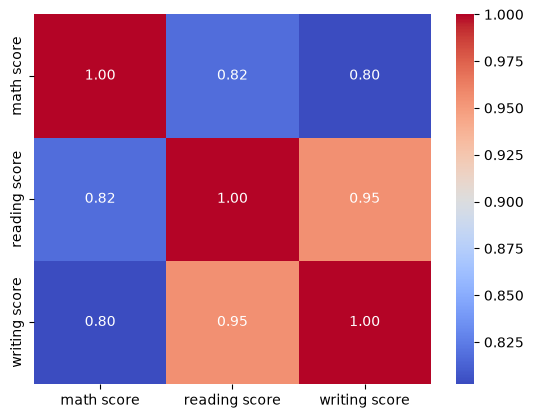

In [17]:
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')  # buat heatmap korelasi antar-kolom numerik
plt.show()

<Axes: >

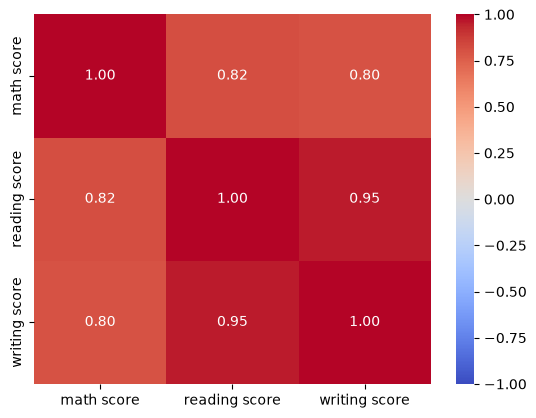

In [18]:
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0)    # skala dikunci -1..1; putih = 0, merah = positif, biru = negatif

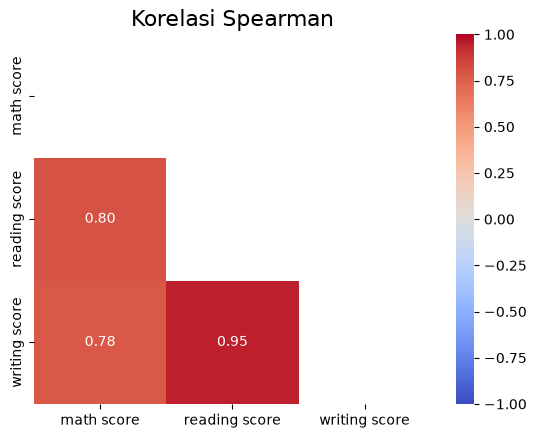

In [19]:
import numpy as np

korelasi = df[num_cols].corr(method='spearman')

mask = np.triu(np.ones_like(korelasi, dtype=bool))  # buat mask untuk menutupi segitiga atas
sns.heatmap(korelasi, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)

plt.title('Korelasi Spearman', fontsize=16)
plt.show()

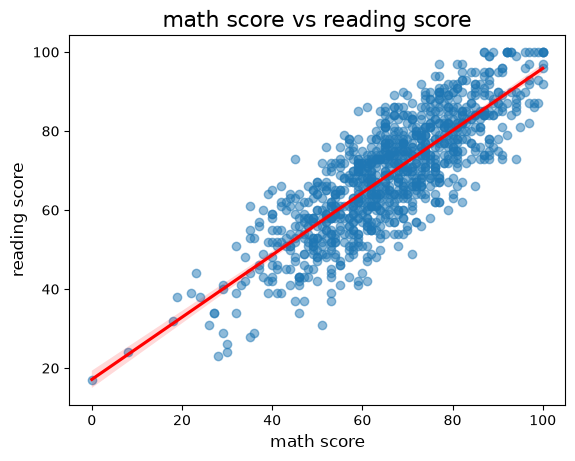

In [20]:
sns.regplot(data=df, x='math score', y='reading score', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})

plt.title('math score vs reading score', fontsize=16)
plt.xlabel('math score', fontsize=12)
plt.ylabel('reading score', fontsize=12)
plt.show()

### 3c. Perbandingan antar kelompok	

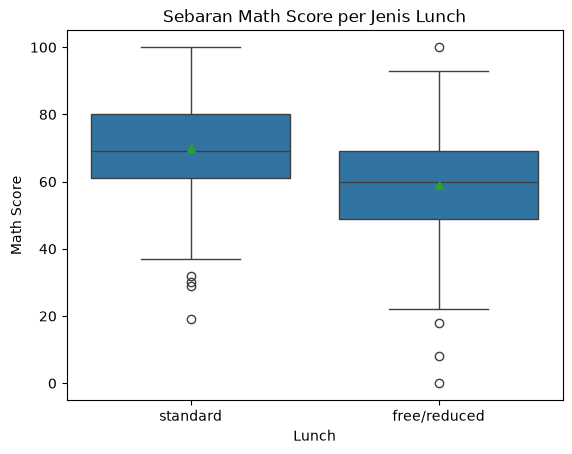

In [21]:
#D2 Boxplot dengan titik rata-rata

urut = (df.groupby('lunch')['math score']
        .mean()
        .sort_values(ascending=False)
        .index)                                  # urutan kategori lunch, rata-rata tertinggi dulu

sns.boxplot(data=df, x='lunch', y='math score',
            order=urut,
            showmeans=True)
plt.title('Sebaran Math Score per Jenis Lunch')
plt.xlabel('Lunch')
plt.ylabel('Math Score')
plt.show()

In [22]:
#B3 Hitung outlier tanpa langsung membuangnya

def hitung_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 -q1
    bawah, atas = q1 -1.5 * iqr, q3 + 1.5 * iqr
    return ((s < bawah) | (s > atas)).sum()

print(df[num_cols].apply(hitung_outlier))

math score       8
reading score    6
writing score    5
dtype: int64


 emang ada beberapa outlier tapi itu harus di pertahankan karena kan bisa jadi emang ada murid dengan nilai rendah

Temuan 1. Siswa dengan lunch standard rata-rata mendapat math score 70,0, sedangkan siswa dengan lunch free/reduced mendapat 58,9 (selisih 11,1 poin). Ini selisih terbesar di antara kolom yang hanya punya dua kategori. Catatan: lunch mungkin mewakili faktor lain seperti kondisi ekonomi keluarga, jadi ini belum hubungan sebab-akibat. Signifikansi dan ukuran efek belum diuji.

In [23]:
#Fungsi hitung_outlier mengembalikan jumlah. 
# Untuk menampilkan barisnya, kamu butuh versi yang mengembalikan True/False per baris:

def tandai_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (s < bawah) | (s > atas)          # tanpa .sum(): hasilnya True/False per baris

for col in num_cols:
    mask = tandai_outlier(df[col])           # True untuk baris yang outlier di kolom ini
    print(f'--- {col}: {mask.sum()} outlier ---')
    print(df.loc[mask, [col]].sort_values(col), '\n')

--- math score: 8 outlier ---
     math score
59            0
980           8
17           18
787          19
145          22
842          23
338          24
466          26 

--- reading score: 6 outlier ---
     reading score
59              17
327             23
980             24
596             24
76              26
211             28 

--- writing score: 5 outlier ---
     writing score
59              10
596             15
327             19
76              22
980             23 



In [24]:
#Melihat siswa yang sama di ketiga skor
#Ini berguna untuk mengecek apakah satu siswa rendah di semua mata pelajaran:

mask_any = df[num_cols].apply(tandai_outlier).any(axis=1)   # True jika outlier di minimal satu skor
print(df.loc[mask_any])                                      # tampilkan baris lengkap, semua kolom

     gender race/ethnicity parental level of education         lunch  \
17   female        group B            some high school  free/reduced   
59   female        group C            some high school  free/reduced   
76     male        group E            some high school      standard   
145  female        group C                some college  free/reduced   
211    male        group C                some college  free/reduced   
327    male        group A                some college  free/reduced   
338  female        group B            some high school  free/reduced   
466  female        group D          associate's degree  free/reduced   
596    male        group B                 high school  free/reduced   
787  female        group B                some college      standard   
842  female        group B                 high school  free/reduced   
980  female        group B                 high school  free/reduced   

    test preparation course  math score  reading score  writing

### 3d. Cek multivariat

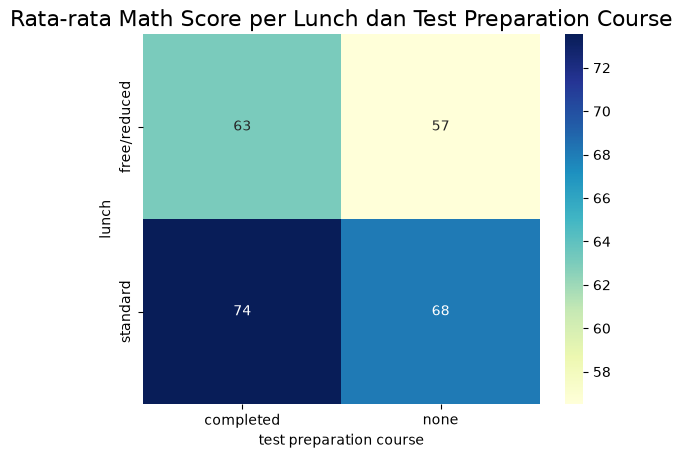

In [25]:
# E2 Dua kategori vs satu angka: pivot table dan heatmap

tabel = df.pivot_table(index='lunch', # isi baris
                       columns='test preparation course',  # isi kolom
                       values='math score', # angka yang dirata-ratakan
                       aggfunc='mean') # isi sel = rata-rata

sns.heatmap(tabel, annot=True, fmt='.0f', cmap = 'YlGnBu')
plt.title('Rata-rata Math Score per Lunch dan Test Preparation Course', fontsize=16)
plt.show()

Siswa dengan lunch standard rata-rata unggul sekitar 11 poin di math score dibanding free/reduced (Welch t = 11,48, p < 0,0001, d = 0,78, efek mendekati besar). Siswa yang menyelesaikan test preparation course unggul sekitar 6 poin (p < 0,0001, d = 0,38, efek kecil-sedang). Hubungan ini bersifat asosiasi, bukan bukti sebab-akibat.

In [26]:
pd.crosstab(df['lunch'], df['test preparation course'])

test preparation course,completed,none
lunch,,
free/reduced,131,224
standard,227,418


In [27]:
tabel2 = df.pivot_table(index='parental level of education',
                        columns='lunch',
                        values='math score',
                        aggfunc='mean')
print(tabel2.round(1))

pd.crosstab(df['parental level of education'], df['lunch'])   # jumlah siswa tiap sel

lunch                        free/reduced  standard
parental level of education                        
associate's degree                   62.6      70.7
bachelor's degree                    63.0      73.2
high school                          54.5      66.4
master's degree                      61.2      75.6
some college                         60.1      70.9
some high school                     53.9      68.4


lunch,free/reduced,standard
parental level of education,,
associate's degree,77,145
bachelor's degree,44,74
high school,70,126
master's degree,24,35
some college,79,147
some high school,61,118


## 4. Uji Statistik

In [28]:
# F1 Dua kelompok: Welch t-test, Mann-Whitney, dan Cohen's d (lunch)

a = df.loc[df['lunch'] == 'standard', 'math score']       # math score siswa lunch standard
b = df.loc[df['lunch'] == 'free/reduced', 'math score']   # math score siswa lunch free/reduced

t, p = stats.ttest_ind(a, b, equal_var=False)             # Welch t-test
print(f'Welch t-test: t = {t:.3f}, p = {p:.4f}')

def cohens_d(a, b):
    n1, n2 = len(a), len(b)
    var_gabung = ((n1 - 1) * a.var(ddof=1) +
                  (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2)
    return (a.mean() - b.mean()) / np.sqrt(var_gabung)

print('d =', round(cohens_d(a, b), 3))

u, p_u = stats.mannwhitneyu(a, b, alternative='two-sided')  # Mann-Whitney U test
print(f'Mann-Whitney: U = {u:.0f}, p = {p_u:.4f}')

Welch t-test: t = 11.484, p = 0.0000
d = 0.782
Mann-Whitney: U = 161077, p = 0.0000


In [29]:
# F1 Dua kelompok: test preparation course (completed vs none)

a = df.loc[df['test preparation course'] == 'completed', 'math score']
b = df.loc[df['test preparation course'] == 'none', 'math score']

t, p = stats.ttest_ind(a, b, equal_var=False)             # Welch t-test
print(f'Welch t-test: t = {t:.3f}, p = {p:.4f}')

print('d =', round(cohens_d(a, b), 3))                    # ukuran efek

u, p_u = stats.mannwhitneyu(a, b, alternative='two-sided')  # Mann-Whitney U
print(f'Mann-Whitney: U = {u:.0f}, p = {p_u:.4f}')


Welch t-test: t = 5.787, p = 0.0000
d = 0.376
Mann-Whitney: U = 138412, p = 0.0000


In [30]:
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [31]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 5. Pemodelan

### 5a. Persiapan data

In [32]:
# M1 Siapkan X dan Y

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score


y = df['math score'] # yang mau di prediksi (target)
X = df.drop(columns=['math score', 'reading score', 'writing score']) 
# bahan untuk menebak

In [33]:
#M2 Ubah kategori menjadi angka (encoding) agar bisa dipakai model machine learning

X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.shape)
X.head()

(1000, 12)


,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,0,1,0,0,0,1,0,0,0,0,1,1
1,0,0,1,0,0,0,0,0,1,0,1,0
2,0,1,0,0,0,0,0,1,0,0,1,1
3,1,0,0,0,0,0,0,0,0,0,0,1
4,1,0,1,0,0,0,0,0,1,0,1,1


1 = ya
0 = tidak

1 = laki
0 = pr



In [34]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


berdasarkan perbandingan antara data yang sudah di encoding, hasilnya sama dengan data yang belum di encoding, pada baris 0 bisa di lihat dan di bandingkan, bahwa hasilnya sama

In [35]:
X.columns.tolist()

#untuk cek kolom apa aja


['gender_male',
 'race/ethnicity_group B',
 'race/ethnicity_group C',
 'race/ethnicity_group D',
 'race/ethnicity_group E',
 "parental level of education_bachelor's degree",
 'parental level of education_high school',
 "parental level of education_master's degree",
 'parental level of education_some college',
 'parental level of education_some high school',
 'lunch_standard',
 'test preparation course_none']

In [36]:
# M3 Bagi data latih dan data uji

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(800, 12) (200, 12)


### 5b. Baseline

In [37]:
#M4 Baseline: tebak rata-rata untuk semua siswa

base = np.full(len(y_test), y_train.mean()) # buat array sepanjang y_test, semua isinya rata-rata y_train

print('MAE baseline:', round(mean_absolute_error(y_test, base), 2)) 
# hitung rata-rata |nilai asli - tebakan| dari 200 siswa uji, bulatkan 2 desimal
print('R2 baseline:', round(r2_score(y_test, base), 3))
# porsi variasi nilai yang dijelaskan (0 = sama dengan menebak rata-rata)

MAE baseline: 12.34
R2 baseline: -0.017


MAE adalah rata-rata selisih mutlak antara tebakan dan nilai asli, dalam satuan poin nilai. MAE 12 berarti tebakan rata-rata meleset 12 poin.

R² adalah porsi variasi yang berhasil dijelaskan model. Untuk baseline, nilainya sekitar 0 (bisa sedikit negatif).

MAE baseline = 12.34: kalau kita menebak rata-rata data latih untuk semua siswa, tebakan itu meleset sekitar 12 poin dari nilai asli. Ini masuk akal, karena math score menyebar cukup lebar (standar deviasinya sekitar 15).

R² baseline = -0,017: tebakan rata-rata menjelaskan hampir 0% variasi nilai. Nilainya sedikit negatif karena rata-rata data latih tidak persis sama dengan rata-rata data uji. Itu normal untuk baseline.

Angka ini adalah batas yang harus dikalahkan. Model yang berguna harus punya MAE di bawah 12,34 dan R² di atas 0. Kalau tidak, model itu tidak lebih baik daripada menebak rata-rata.

### 5c. Linear Regression

In [38]:
#M5 latih linear regression dan bandingkan dengan baseline

from sklearn.linear_model import LinearRegression

model = LinearRegression() # buat model kosong, belum belajar apa-apa
model.fit(X_train, y_train) # model belajar pola dari 800 siswa data latih

pred = model.predict(X_test) # tebak math score 200 siswa uji (belum pernah dilihat model)

print('MAE model: ', round(mean_absolute_error(y_test, pred), 2)) 
# porsi variasi nilai yang dijelaskan (0 = sama dengan menebak rata-rata)
print('R2 model: ', round(r2_score(y_test, pred), 3))
# porsi variasi nilai yang dijelaskan model (1 = sempurna)

MAE model:  11.27
R2 model:  0.176


MAE (Mean Absolute Error) menjawab satu pertanyaan: rata-rata tebakan kita meleset berapa poin? Hitungannya tiga langkah:

Untuk tiap siswa, hitung selisih antara nilai asli dan tebakan, lalu abaikan tanda plus atau minus (nilai mutlak).
Jumlahkan semua selisih itu.
Bagi dengan jumlah siswa.

Modelmu mengalahkan baseline. Meleset berkurang sekitar 1,1 poin (dari 12,3 ke 11,3), dan R² naik dari sekitar 0 ke 0,18.
Perbaikannya nyata tapi kecil. Modelmu menjelaskan sekitar 18% variasi nilai math, jadi sekitar 82% masih tidak terjelaskan. Tebakannya masih meleset sekitar 11 poin. Ini wajar, karena kita hanya memakai data demografi dan sengaja membuang reading serta writing score.
Artinya untuk EDA-mu. lunch, test prep, dan latar belakang memang berhubungan dengan nilai, tapi tidak cukup untuk menebak nilai seorang siswa. Dua siswa dengan profil sama bisa punya nilai yang sangat berbeda. Ini sejalan dengan sebaran besar di dalam tiap kelompok pada boxplot.
Hasilnya bergantung pada 200 siswa uji. Kalau random_state diganti, angkanya bisa bergeser sedikit. Nanti kita bisa memakai cross-validation untuk hasil yang lebih stabil.

Angka itu dari R² = 0,176 di outputmu. R² adalah porsi variasi nilai yang berhasil dijelaskan model, jadi bagian yang belum terjelaskan adalah sisanya:

Dijelaskan model: 0,176, atau sekitar 18%.
Belum dijelaskan: 1 - 0,176 = 0,824, atau sekitar 82%.

Arti “variasi” di sini

Nilai math siswa berbeda-beda: ada yang 30, ada yang 90. Variasi itu adalah seberapa jauh nilai tiap siswa dari rata-rata. R² mengukur seberapa banyak sebaran itu bisa dijelaskan oleh fitur yang kita pakai (lunch, test prep, dan lainnya).

Hitungannya membandingkan dua jumlah kesalahan:

R² = 1 - (kesalahan model) / (kesalahan kalau cuma menebak rata-rata)

Kalau model sama buruknya dengan menebak rata-rata, rasionya 1, jadi R² = 0. Kalau model sempurna, kesalahannya 0, jadi R² = 1. Di hasilmu, kesalahan model sekitar 82% dari kesalahan tebakan rata-rata, jadi R² = 0,18.

Kamu bisa membuktikannya sendiri:

In [39]:
# R2 manual, untuk memahami artinya
sisa_model = ((y_test - pred) ** 2).sum()                 # total kuadrat selisih nilai asli vs tebakan model
sisa_rata2 = ((y_test - y_test.mean()) ** 2).sum()        # total kuadrat selisih nilai asli vs tebakan rata-rata
print('Kesalahan model dibanding rata-rata:', round(sisa_model / sisa_rata2, 3))   # sekitar 0,82
print('R2 manual:', round(1 - sisa_model / sisa_rata2, 3))                         # harus sama dengan r2_score, yaitu 0,176

Kesalahan model dibanding rata-rata: 0.824
R2 manual: 0.176


Apa isi “82% yang belum terjelaskan”

Itu variasi yang tidak bisa dijelaskan data demografi kita. Misalnya kebiasaan belajar, minat pada matematika, kondisi saat ujian, atau perbedaan antarindividu yang tidak tercatat di tabel. Kita tidak tahu persisnya apa penyebabnya, karena datanya tidak memuat hal itu.

Karena R² dihitung dari data uji dengan 200 siswa, angka 18% ini juga perkiraan yang bisa bergeser sedikit kalau pembagian datanya berbeda.

Setelah itu, cocokkan hasilnya dengan EDA-mu. Apakah lunch_standard dan test preparation course_none memang yang koefisiennya paling besar? Kirim output M5 dan M6 kalau sudah jalan. 

untuk M6

In [40]:
# M6 Koefisien: seberapa besar tiap kolom menggeser tebakan

koef = pd.Series(model.coef_, index=X.columns).sort_values() 
# pasangkan nama kolom dengan koefisiennya, urutkan kecil ke besar
print(koef.round(2))
print('Intercept:', round(model.intercept_, 2)) 
# tebakan dasar untuk siswa dengan semua kolom = 0

test preparation course_none                     -5.87
parental level of education_high school          -4.09
parental level of education_some high school     -2.90
parental level of education_some college         -0.15
race/ethnicity_group B                            0.18
race/ethnicity_group C                            0.60
parental level of education_master's degree       1.07
parental level of education_bachelor's degree     3.12
race/ethnicity_group D                            3.61
gender_male                                       4.52
race/ethnicity_group E                            9.08
lunch_standard                                   11.52
dtype: float64
Intercept: 59.09


Koefisien dibaca sebagai selisih terhadap kategori acuan, seperti yang kita bahas di M2. Misalnya, koefisien lunch_standard = +10 berarti siswa lunch standard rata-rata 10 poin di atas free/reduced, dengan kolom lainnya dianggap sama. Intercept adalah tebakan untuk siswa acuan: perempuan, group A, orang tua associate’s degree, free/reduced, dan test prep completed.

Benar, lunch_standard (+11,52) koefisien terbesar. Tapi test preparation course_none (-5,87) bukan yang “paling kecil” dalam arti pengaruhnya. Tanda minus hanya berarti arahnya menurunkan nilai. Ukuran pengaruhnya dilihat dari angka tanpa tanda, dan dengan begitu ia ada di urutan ketiga setelah lunch_standard (11,52) dan race/ethnicity_group E (9,08). Pertanyaanku sebelumnya kurang tepat karena tidak menyebut hal ini. Semua kolom ini 0/1, jadi besarnya bisa dibandingkan langsung.

Kenapa kita mencocokkan dengan EDA

Ini cek konsistensi dengan satu pertanyaan: apakah temuan EDA tetap berlaku setelah faktor lain ikut diperhitungkan?

Di EDA, selisih rata-rata dihitung satu faktor sekali (misalnya lunch saja). Bisa saja selisih itu sebenarnya efek faktor lain yang ikut menumpang.
Koefisien model dihitung sekaligus dengan semua faktor lain dianggap sama.

Kalau keduanya sepakat, temuanmu kuat. Kalau berbeda jauh, ada faktor yang saling bercampur (confounding) dan perlu diselidiki.

Hasilnya: EDA dan model sepakat

Faktor	Selisih di EDA	Koefisien model
lunch standard vs free/reduced	sekitar 11,1	+11,52
test prep none vs completed	sekitar -5,6	-5,87

Angkanya hampir sama. Ini konsisten dengan hasil pivot tadi: selisih lunch sekitar 11 dan selisih test prep sekitar 6 tetap ada di dalam tiap kelompok. Jadi kedua temuan itu bukan artefak faktor lain.

## Kesimpulan

 Dengan faktor lain dianggap sama, siswa dengan lunch standard rata-rata 11,5 poin lebih tinggi di math dan siswa yang tidak mengikuti test preparation course rata-rata 5,9 poin lebih rendah. Besarnya hampir sama dengan selisih mentah di EDA, sehingga kedua temuan itu tidak disebabkan faktor lain. Model dengan data demografi hanya menjelaskan sekitar 18% variasi nilai (R² = 0,18), sehingga sebagian besar penyebab perbedaan nilai tidak tercakup di data.

Metode	Ada target?	Contoh
Regresi	

Ya, berupa angka	Tebak math score (0-100). Ini yang kita kerjakan

Klasifikasi	Ya, berupa kategori	Tebak lulus atau tidak lulus

Clustering	Tidak ada	Kelompokkan siswa yang mirip tanpa label apa pun

Kita punya target (math score), jadi ini supervised learning, sama dengan yang kita bahas soal “jika supervised”. Karena targetnya angka, jenisnya regresi. Kalau kita mengubah target menjadi “math score ≥ 60 atau tidak”, itu menjadi klasifikasi. Clustering baru dipakai kalau kita tidak punya target dan ingin menemukan kelompok alami di data.

Tujuan pengolahan data ini

Ada dua tujuan, dan keduanya sudah kamu lakukan:

Memahami: faktor apa yang berhubungan dengan math score, dan seberapa kuat? Ini dijawab oleh EDA, uji t/Mann-Whitney, dan koefisien model. Hasilnya: lunch (sekitar 11 poin) dan test prep (sekitar 6 poin) berhubungan nyata, dan pola ini tetap ada setelah faktor lain dihitung.


Menebak: seberapa baik math score bisa ditebak dari data demografi? Ini dijawab oleh model, baseline, MAE, dan R². Hasilnya: lebih baik dari tebakan rata-rata, tapi baru menjelaskan sekitar 18% variasi nilai.

Dataset ini dipakai untuk latihan, jadi belum ada keputusan bisnis di baliknya. Tujuan sebenarnya adalah melatih alur kerjanya: pertanyaan, EDA, uji, model, baseline, evaluasi, kesimpulan.

Data demografi adalah data tentang latar belakang dan karakteristik seseorang, bukan tentang apa yang ia kerjakan atau capai. Misalnya jenis kelamin, usia, daerah asal, kelompok sosial, pekerjaan atau pendidikan orang tua, dan kondisi ekonomi.

Kolom yang kita buang dari fitur adalah reading score dan writing score. Keduanya hasil ujian, yaitu nilai yang diperoleh siswa. Karena sangat berkorelasi dengan math score, memasukkannya akan membuat model terlalu mudah menebak, dan di dunia nyata nilai itu sering belum tersedia saat kita ingin memprediksi.

Jadi pertanyaan modelnya sebenarnya: “Kalau kita hanya tahu latar belakang siswa dan apakah ia ikut kursus, seberapa baik math score-nya bisa ditebak?” Jawabannya sejauh ini: sedikit lebih baik dari menebak rata-rata (R² = 0,18), tapi belum cukup untuk menebak nilai individu dengan tepat.

### 5d. Model dengan reading dan writing score

In [41]:
# M7 Model dengan reading & writing score ikut jadi fitur

X2 = df.drop(columns=['math score']) # semua kolom kecuali target (reading dan writing ikut)
X2 = pd.get_dummies(X2, drop_first=True, dtype=int)  # ubah kategori jadi kolom 0/1

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42 # bagi data dengan pengacakan yang sama seperti M3, jadi perbandingannya adil
)

model2 = LinearRegression() # buat model kosong, belum belajar apa-apa
model2.fit(X2_train, y2_train) # model belajar dari 800 siswa data latih

pred2 = model2.predict(X2_test)  # tebak math score 200 siswa uji

print('MAE model 2:', round(mean_absolute_error(y2_test, pred2), 2)) # rata-rata meleset berapa poin
print('R2 model 2: ', round(r2_score(y2_test, pred2), 3)) # porsi variasi yang dijelaskan

MAE model 2: 4.21
R2 model 2:  0.88


Kalau tujuannya menebak math score dari nilai mata pelajaran lain, model ini sudah bagus. Kalau tujuannya memahami faktor latar belakang yang berhubungan dengan nilai, Model 1 yang lebih relevan. Karena itu hasil ini kita tulis sebagai catatan tambahan, bukan sebagai kesimpulan utama.

In [42]:
# M8 Koefisien model 2: apakah lunch dan test prep masih berpengaruh?

koef2 = pd.Series(model2.coef_, index=X2.columns).sort_values()
print(koef2.round(2))
print('Intercept: ', round(model2.intercept_, 2))

parental level of education_master's degree      -1.40
parental level of education_bachelor's degree    -0.72
race/ethnicity_group C                           -0.63
race/ethnicity_group D                           -0.61
reading score                                     0.24
race/ethnicity_group B                            0.36
writing score                                     0.72
parental level of education_some high school      0.76
parental level of education_high school           0.93
parental level of education_some college          1.00
test preparation course_none                      3.29
lunch_standard                                    3.51
race/ethnicity_group E                            4.89
gender_male                                      13.06
dtype: float64
Intercept:  -10.91


Model 1 untuk memahami faktor latar belakang yang berhubungan dengan math.
Model 2 untuk memprediksi math dari nilai lain (R² 0,88).

Setelah reading dan writing score dimasukkan ke model, R² naik menjadi 0,88, tetapi pengaruh lunch menyusut dari 11,5 ke 3,5 poin dan tanda koefisien test prep berbalik. Ini menunjukkan koefisien bergantung pada variabel lain di model, sehingga tidak boleh ditafsirkan sebagai sebab-akibat.

Hasil kita masih dari satu pembagian data (200 siswa uji). Cross-validation mengulang pengujian lima kali dengan pembagian berbeda supaya kita tahu apakah R² 0,18 dan 0,88 stabil.

### 5e. Cross-validation

In [43]:
# M9 Cross-validation: uji Model 1 dan Model 2 dengan 5 pembagian data berbeda

from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42) 
# bagi data jadi 5 bagian, acak dulu, hasil bisa diulang

skor1 = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2')  
 # latih dan uji 5 kali, catat R2 tiap kali (Model 1)
skor2 = cross_val_score(LinearRegression(), X2, y, cv=kf, scoring='r2')
# sama, untuk Model 2

print('Model 1 R2 tiap lipatan  :', skor1.round(3))
# 5 angka R2, lihat seberapa beda satu sama lain
print('Model 1 rata-rata R2     :', round(skor1.mean(), 3)) # rata-rata dari 5 uji
print('Model 2 R2 tiap lipatan  :', skor2.round(3))
print('Model 2 rata-rata R2     :', round(skor2.mean(), 3))


Model 1 R2 tiap lipatan  : [0.176 0.255 0.274 0.184 0.233]
Model 1 rata-rata R2     : 0.224
Model 2 R2 tiap lipatan  : [0.88  0.862 0.881 0.856 0.88 ]
Model 2 rata-rata R2     : 0.872


Cara membacanya

Model 2 sangat stabil. Kelima angkanya hampir sama (selisih terbesar sekitar 0,025), jadi R² sekitar 0,87 bisa dipercaya dan bukan kebetulan satu pembagian data.

Model 1 bergeser lebih jauh (0,18 sampai 0,27), tapi arahnya konsisten. Semua lipatan jauh di atas 0, jadi temuan intinya tetap: faktor latar belakang menjelaskan sebagian kecil variasi math, sekitar seperlima. Sinyalnya lemah, sehingga komposisi 200 siswa uji lebih berpengaruh pada angkanya. Itu wajar.

Angka 0,176 yang kita dapat dulu hanya satu dari lima kemungkinan. Angka itu di ujung bawah rentang (kemungkinan karena pengacakan yang sama, jadi sama dengan lipatan pertama). Rata-rata 0,224 lebih mewakili kemampuan model sebenarnya.

## Pembaruan kalimat kesimpulan untuk notebook

Dengan 5-fold cross-validation, model yang hanya memakai data latar belakang dan test preparation course menjelaskan rata-rata sekitar 22% variasi math score (R² 0,18 sampai 0,27). Menambahkan reading dan writing score menaikkan R² menjadi sekitar 0,87 (0,86 sampai 0,88) dan hasilnya stabil di semua lipatan.

### 5f. Random Forest

In [44]:
# M10 Random Forest untuk Model 1, diuji dengan cross-validation yang sama

from sklearn.ensemble import RandomForestRegressor 
# ambil model Random Forest dari scikit-learn

rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=10, random_state=42)
# 200 pohon keputusan, tiap daun minimal 10 siswa, hasil bisa diulang

skor_rf = cross_val_score(rf, X, y, cv=kf, scoring='r2')
# latih dan uji 5 kali memakai pembagian kf yang sama dengan M9

print('Random Forest R2 tiap lipatan:', skor_rf.round(3))
# 5 angka R2, bandingkan dengan Model 1 linear
print('Random Forest rata-rata R2   : ', round(skor_rf.mean(), 3)) 
# rata-rata dari 5 uji
print('Linear Regression rata-rata  :', round(skor1.mean(), 3))
# pembanding dari M9 (sekitar 0,224)

Random Forest R2 tiap lipatan: [0.136 0.192 0.219 0.16  0.212]
Random Forest rata-rata R2   :  0.184
Linear Regression rata-rata  : 0.224


In [45]:
# M11 Variabel mana yang paling dipakai Random Forest
rf.fit(X, y) # latih RF di seluruh data hanya untuk melihat kepentingan fitur

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
# pasangkan nama kolom dengan skor kepentingannya, urutkan besar ke kecil

print(imp.round(3).head(6)) # tampilkan 6 teratas

lunch_standard                                  0.395
test preparation course_none                    0.113
race/ethnicity_group E                          0.107
gender_male                                     0.106
parental level of education_high school         0.058
parental level of education_some high school    0.048
dtype: float64


## 6. Kesimpulan

**Pertanyaan:** Faktor apa yang berhubungan dengan math score siswa, dan seberapa baik math score bisa diprediksi?

**Temuan EDA dan uji statistik**
- Siswa dengan lunch standard rata-rata 11 poin lebih tinggi di math (Welch t = 11,48, p < 0,0001, d = 0,78).
- Siswa yang menyelesaikan test preparation course rata-rata 6 poin lebih tinggi (p < 0,0001, d = 0,38).
- Kedua selisih tetap ada di semua tingkat pendidikan orang tua dan di kedua kelompok test prep, jadi bukan artefak faktor lain.

**Pemodelan (5-fold cross-validation, target math score)**
- Baseline (tebak rata-rata): MAE 12,34.
- Linear Regression dengan data latar belakang dan test prep: R² rata-rata 0,22.
- Random Forest: R² rata-rata 0,18, tidak lebih baik dari regresi linear.
- Dengan reading dan writing score sebagai fitur: R² rata-rata 0,87, tetapi ini nilai ujian lain yang sangat mirip dengan target.

**Batasan**
- Hubungan yang ditemukan bersifat asosiasi, bukan sebab-akibat.
- Data latar belakang hanya menjelaskan sekitar seperlima variasi nilai.
- Koefisien bergantung pada variabel lain di model (tanda koefisien test prep berbalik saat reading dan writing dimasukkan).

In [46]:
# Cetak versi pustaka yang dipakai, untuk requirements.txt
import pandas, numpy, matplotlib, seaborn, scipy, sklearn          # impor semua pustaka utama proyek

for m in [pandas, numpy, matplotlib, seaborn, scipy, sklearn]:     # ulangi untuk tiap pustaka
    print(f'{m.__name__}=={m.__version__}')                        # cetak "nama==versi", format yang dipakai pip

pandas==3.0.6
numpy==2.5.3
matplotlib==3.11.2
seaborn==0.13.2
scipy==1.18.1
sklearn==1.9.1
